# Classical Models WITHOUT Encoder - Training Notebook

This notebook demonstrates training classical models (ShallowCNN and ResNet18) without encoder preprocessing.

**Model Variants:**
- `ShallowCNN`: 3-layer CNN processing raw images directly
- `ClassicalModel`: ResNet18-based model with transfer learning

These models learn features from scratch without pre-trained encoder.

## 1. Setup and Imports

In [79]:
import os
import sys
import torch
import torch.nn as nn
import torch.optim as optim
from datetime import datetime

# Add project root to path
project_root = '/home/eflammere/HybridEmbeddingsForBreastCancerDetection'
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.utils.setup import setup_device, setup_directories
from src.utils.dataloader import BreastMNISTLoader, BCDRLoader, INbreastLoader, BUSUCLMLoader
from src.utils.training import training_loop, test_model
from src.models.main.classical import ClassicalModel, ShallowCNN

print("✓ Imports successful")

✓ Imports successful


## 2. Configuration

In [80]:
# Training Configuration
CONFIG = {
    # Model settings
    'model_type': 'shallow',  # 'shallow' or 'resnet'
    'num_classes': 2,
    'input_channels': 1,  # 1 for grayscale, 3 for RGB
    
    # Dataset settings
    'dataset': 'breastmnist',  # 'breastmnist', 'bcdr', 'inbreast', or 'busuclm'
    'batch_size': 16,
    'image_size': 224,
    
    # Training settings
    'epochs': 100,
    'learning_rate': 1e-3,
}

print("Configuration:")
for key, value in CONFIG.items():
    print(f"  {key}: {value}")

Configuration:
  model_type: shallow
  num_classes: 2
  input_channels: 1
  dataset: breastmnist
  batch_size: 16
  image_size: 224
  epochs: 100
  learning_rate: 0.001


## 3. Setup Device and Directories

In [81]:
device = setup_device()
dirs = setup_directories()

# Create save directory
dataset_mapping = {
    'breastmnist': 'BreastMNIST',
    'bcdr': 'BCDR',
    'inbreast': 'INbreast',
    'busuclm': 'BUSUCLM'
}
dataset_name = dataset_mapping.get(CONFIG['dataset'], 'BreastMNIST')
model_type = CONFIG['model_type']
save_dir = os.path.join(
    dirs.get("project_dir", "."),
    "experiments", "models", dataset_name, "classical", model_type
)
os.makedirs(save_dir, exist_ok=True)

print(f"Device: {device}")
print(f"Save directory: {save_dir}")

Using: NVIDIA GeForce RTX 4070 Ti SUPER
CUDA: 12.4
Device: cuda
Save directory: ./experiments/models/BreastMNIST/classical/shallow


## 4. Load Dataset

In [82]:
if CONFIG['dataset'] == 'bcdr':
    loader = BCDRLoader(
        batch_size=CONFIG['batch_size'],
        image_size=CONFIG['image_size'],
        root_dir='src/data/BCDR/png'
    )
    print(f"✓ BCDR dataset loaded")
elif CONFIG['dataset'] == 'inbreast':
    loader = INbreastLoader(
        batch_size=CONFIG['batch_size'],
        image_size=CONFIG['image_size'],
        root_dir='src/data/INbreast/png'
    )
    print(f"✓ INbreast dataset loaded")
elif CONFIG['dataset'] == 'busuclm':
    loader = BUSUCLMLoader(
        batch_size=CONFIG['batch_size'],
        image_size=CONFIG['image_size'],
        root_dir='src/data/BUS-UCLM/png'
    )
    print(f"✓ BUSUCLM dataset loaded")
else:
    loader = BreastMNISTLoader(
        batch_size=CONFIG['batch_size'],
        image_size=CONFIG['image_size'],
    )
    print(f"✓ BreastMNIST dataset loaded")

train_loader, test_loader, val_loader = loader.get_dataloaders()

print(f"  Training batches: {len(train_loader)}")
print(f"  Validation batches: {len(val_loader)}")
print(f"  Test batches: {len(test_loader)}")

✓ BreastMNIST dataset loaded
Using downloaded and verified file: /home/eflammere/.medmnist/breastmnist_224.npz
Using downloaded and verified file: /home/eflammere/.medmnist/breastmnist_224.npz
Using downloaded and verified file: /home/eflammere/.medmnist/breastmnist_224.npz
  Training batches: 35
  Validation batches: 5
  Test batches: 10


## 5. Create Model WITHOUT Encoder

In [83]:
if CONFIG['model_type'] == 'shallow':
    model = ShallowCNN(
        num_classes=CONFIG['num_classes'],
        input_channels=CONFIG['input_channels']
    ).to(device)
    model_name = 'shallow_no_encoder'
else:
    model = ClassicalModel(
        num_classes=CONFIG['num_classes']
    ).to(device)
    model_name = 'resnet'

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"✓ Model created: {model.__class__.__name__}")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  All parameters are trainable (no frozen encoder)")

✓ Model created: ShallowCNN
  Total parameters: 93,378
  Trainable parameters: 93,378
  All parameters are trainable (no frozen encoder)


## 6. Setup Training

In [84]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'])

print(f"✓ Training setup complete")
print(f"  Loss: CrossEntropyLoss")
print(f"  Optimizer: Adam (lr={CONFIG['learning_rate']})")
print(f"  Epochs: {CONFIG['epochs']}")

✓ Training setup complete
  Loss: CrossEntropyLoss
  Optimizer: Adam (lr=0.001)
  Epochs: 100


## 7. Train Model

In [85]:
print(f"\n{'='*80}")
print(f"Starting Training - {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"{'='*80}\n")

history = training_loop(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    num_epochs=CONFIG['epochs'],
    save_dir=save_dir,
    model_name=model_name,
    extract_features=False,
    save_best_only=True,
    save_all_epochs=False
)

print(f"\n{'='*80}")
print(f"Training Complete - {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"{'='*80}")


Starting Training - 2026-04-16 10:40:46

Epoch 1/100



Epoch 1 Summary:
  Train - Loss: 0.6238, Acc: 0.6630
  Val   - Loss: 0.8829, Acc: 0.4231, Precision: 1.0000, Recall: 0.2105, F1: 0.3478, AUC: 0.7644
  ✓ New best model saved (val_acc: 0.4231) at ./experiments/models/BreastMNIST/classical/shallow/best_shallow_no_encoder.pth
Epoch 2/100



Epoch 2 Summary:
  Train - Loss: 0.5839, Acc: 0.7399
  Val   - Loss: 0.5466, Acc: 0.7308, Precision: 0.8750, Recall: 0.7368, F1: 0.8000, AUC: 0.7895
  ✓ New best model saved (val_acc: 0.7308) at ./experiments/models/BreastMNIST/classical/shallow/best_shallow_no_encoder.pth
Epoch 3/100



Epoch 3 Summary:
  Train - Loss: 0.5946, Acc: 0.7125
  Val   - Loss: 0.5114, Acc: 0.7949, Precision: 0.9184, Recall: 0.7895, F1: 0.8491, AUC: 0.8346
  ✓ New best model saved (val_acc: 0.7949) at ./experiments/models/BreastMNIST/classical/shallow/best_shallow_no_encoder.pth
Epoch 4/100



Epoch 4 Summary:
  Train - Loss: 0.5838, Acc: 0.6868
  Val   - Loss: 0.5752, Acc: 0.6667, Precision: 1.0000, Recall: 0.5439, F1: 0.7045, AUC: 0.8922
Epoch 5/100


...


Epoch 96 Summary:
  Train - Loss: 0.3526, Acc: 0.8608
  Val   - Loss: 0.4107, Acc: 0.7821, Precision: 0.9167, Recall: 0.7719, F1: 0.8381, AUC: 0.9031
Epoch 97/100



Epoch 97 Summary:
  Train - Loss: 0.3674, Acc: 0.8425
  Val   - Loss: 0.4138, Acc: 0.8077, Precision: 0.9565, Recall: 0.7719, F1: 0.8544, AUC: 0.9131
Epoch 98/100



Epoch 98 Summary:
  Train - Loss: 0.3913, Acc: 0.8352
  Val   - Loss: 0.4119, Acc: 0.8205, Precision: 0.9216, Recall: 0.8246, F1: 0.8704, AUC: 0.8972
Epoch 99/100



Epoch 99 Summary:
  Train - Loss: 0.3239, Acc: 0.8681
  Val   - Loss: 0.3709, Acc: 0.8205, Precision: 0.9574, Recall: 0.7895, F1: 0.8654, AUC: 0.9365
Epoch 100/100



Epoch 100 Summary:
  Train - Loss: 0.3893, Acc: 0.8168
  Val   - Loss: 0.7108, Acc: 0.6410, Precision: 0.9677, Recall: 0.5263, F1: 0.6818, AUC: 0.9156

Training Complete - 2026-04-16 10:41:19


## 8. Plot Training History

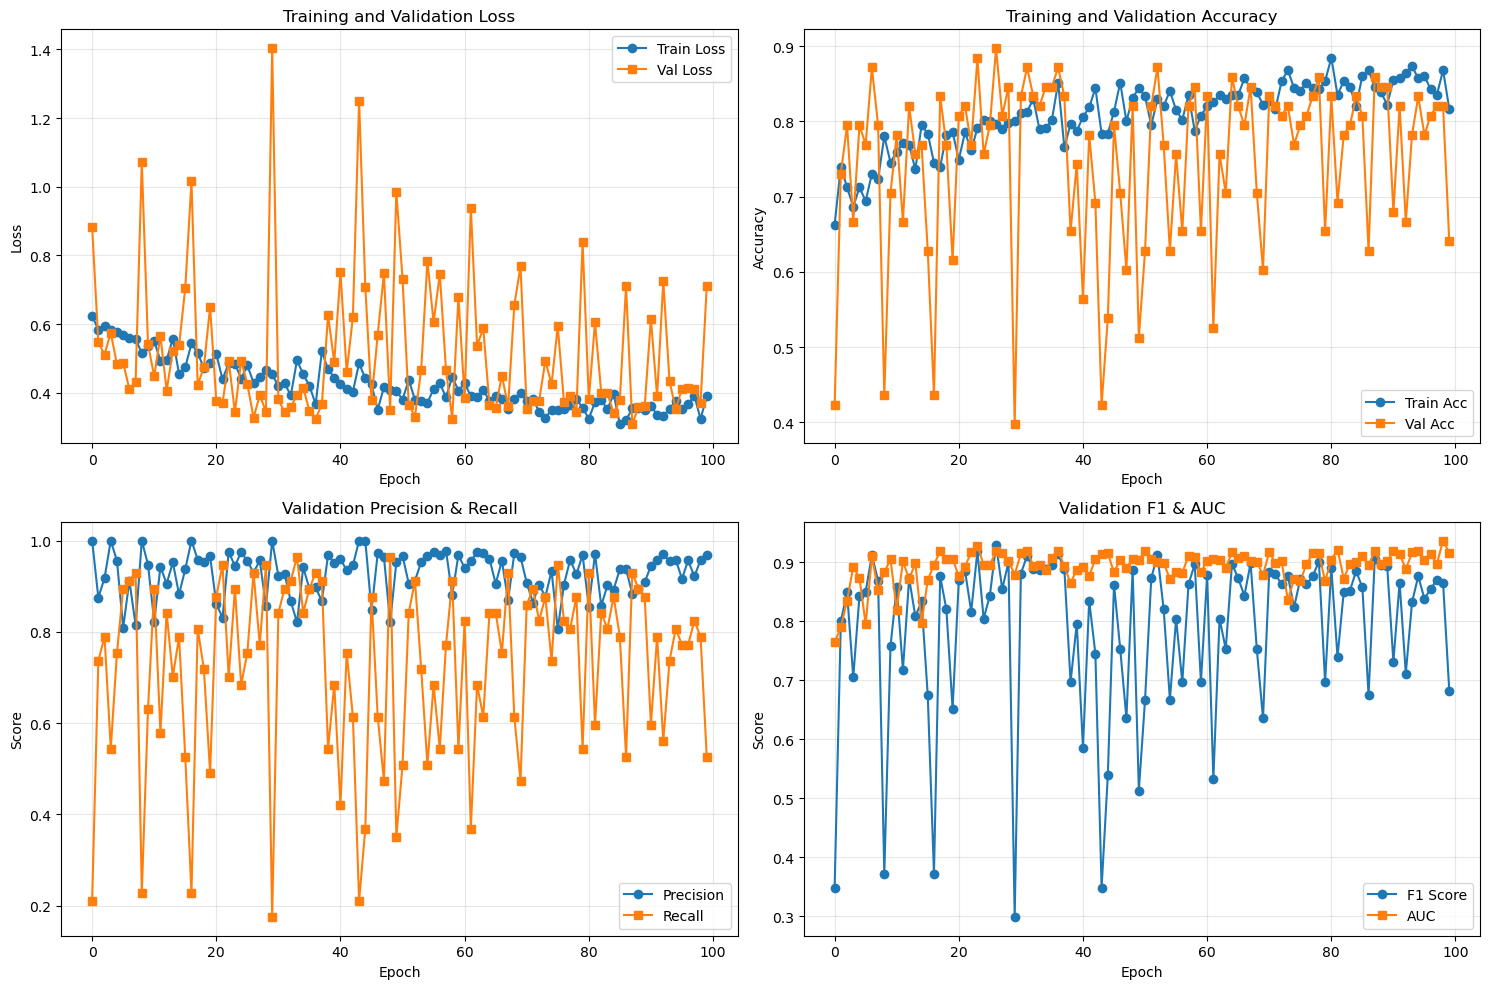

✓ Training curves saved to ./experiments/models/BreastMNIST/classical/shallow/training_history.png


In [86]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Loss
axes[0, 0].plot(history['train_loss'], label='Train Loss', marker='o')
axes[0, 0].plot(history['val_loss'], label='Val Loss', marker='s')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Training and Validation Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Accuracy
axes[0, 1].plot(history['train_acc'], label='Train Acc', marker='o')
axes[0, 1].plot(history['val_acc'], label='Val Acc', marker='s')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].set_title('Training and Validation Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Precision & Recall
axes[1, 0].plot(history['val_precision'], label='Precision', marker='o')
axes[1, 0].plot(history['val_recall'], label='Recall', marker='s')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Score')
axes[1, 0].set_title('Validation Precision & Recall')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# F1 & AUC
axes[1, 1].plot(history['val_f1'], label='F1 Score', marker='o')
axes[1, 1].plot(history['val_auc'], label='AUC', marker='s')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Score')
axes[1, 1].set_title('Validation F1 & AUC')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(save_dir, 'training_history.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"✓ Training curves saved to {save_dir}/training_history.png")

## 9. Load Best Model and Test

In [87]:
# Load best model
model_path = os.path.join(save_dir, f"best_{model_name}.pth")

if os.path.isfile(model_path):
    state = torch.load(model_path, map_location=device)
    model.load_state_dict(state)
    print(f"✓ Loaded best model from {model_path}")
else:
    print("⚠ Warning: No best model found, using final epoch weights")

model.eval()

✓ Loaded best model from ./experiments/models/BreastMNIST/classical/shallow/best_shallow_no_encoder.pth


/tmp/ipykernel_2551375/524847859.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(model_path, map_location=device)


ShallowCNN(
  (conv1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (fc): Linear(in_features=128, out_features=2, bias=True)
)

In [88]:
# Test the model
print(f"\n{'='*80}")
print("Testing Best Model")
print(f"{'='*80}\n")

test_result = test_model(
    model=model,
    dataloader=test_loader,
    criterion=criterion,
    device=device,
    hyperparams=CONFIG
)

# Unpack the tuple (loss, accuracy, precision, recall, f1, auc)
test_loss, test_acc, test_prec, test_rec, test_f1, test_auc = test_result

# Create metrics dictionary for easier access
test_metrics = {
    'loss': float(test_loss),
    'accuracy': float(test_acc),
    'precision': float(test_prec),
    'recall': float(test_rec),
    'f1': float(test_f1),
    'auc': float(test_auc)
}

print("\nTest Results:")
print(f"  Loss: {test_metrics['loss']:.4f}")
print(f"  Accuracy: {test_metrics['accuracy']:.4f}")
print(f"  Precision: {test_metrics['precision']:.4f}")
print(f"  Recall: {test_metrics['recall']:.4f}")
print(f"  F1 Score: {test_metrics['f1']:.4f}")
print(f"  AUC: {test_metrics['auc']:.4f}")


Testing Best Model



Testing: 100%|██████████| 10/10 [00:00<00:00, 219.59it/s]

Test Loss: 0.3941
Accuracy: 0.8397, Precision: 0.8803, Recall: 0.9035, F1: 0.8918, AUC: 0.8626
Macro - Precision: 0.7991, Recall: 0.7851, F1: 0.7916
Micro - Precision: 0.8397, Recall: 0.8397, F1: 0.8397

Test Results:
  Loss: 0.3941
  Accuracy: 0.8397
  Precision: 0.8803
  Recall: 0.9035
  F1 Score: 0.8918
  AUC: 0.8626


In [89]:
# Save test results to text file
results_file = os.path.join(save_dir, f'test_results_{model_name}.txt')

with open(results_file, 'w', encoding='utf-8') as f:
    f.write("="*80 + "\n")
    f.write(f"TEST RESULTS - Classical Model WITHOUT Encoder\n")
    f.write("="*80 + "\n\n")
    
    f.write(f"Timestamp: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n\n")
    
    f.write("MODEL CONFIGURATION\n")
    f.write("-"*80 + "\n")
    f.write(f"Model Type: {model.__class__.__name__}\n")
    f.write(f"Model Variant: {CONFIG['model_type']}\n")
    f.write(f"Dataset: {CONFIG['dataset'].upper()}\n")
    f.write(f"Encoder: None (end-to-end training)\n")
    f.write(f"Total Parameters: {total_params:,}\n")
    f.write(f"Trainable Parameters: {trainable_params:,}\n\n")
    
    f.write("TRAINING HYPERPARAMETERS\n")
    f.write("-"*80 + "\n")
    f.write(f"Epochs: {CONFIG['epochs']}\n")
    f.write(f"Batch Size: {CONFIG['batch_size']}\n")
    f.write(f"Learning Rate: {CONFIG['learning_rate']}\n")
    f.write(f"Image Size: {CONFIG['image_size']}\n")
    f.write(f"Input Channels: {CONFIG['input_channels']}\n")
    f.write(f"Number of Classes: {CONFIG['num_classes']}\n\n")
    
    f.write("BEST VALIDATION METRICS\n")
    f.write("-"*80 + "\n")
    f.write(f"Best Validation Accuracy: {max(history['val_acc']):.4f}\n")
    f.write(f"Best Validation F1 Score: {max(history['val_f1']):.4f}\n")
    f.write(f"Best Validation AUC: {max(history['val_auc']):.4f}\n")
    f.write(f"Best Validation Precision: {max(history['val_precision']):.4f}\n")
    f.write(f"Best Validation Recall: {max(history['val_recall']):.4f}\n\n")
    
    f.write("FINAL TEST METRICS\n")
    f.write("-"*80 + "\n")
    f.write(f"Test Loss: {test_metrics['loss']:.4f}\n")
    f.write(f"Test Accuracy: {test_metrics['accuracy']:.4f}\n")
    f.write(f"Test Precision: {test_metrics['precision']:.4f}\n")
    f.write(f"Test Recall: {test_metrics['recall']:.4f}\n")
    f.write(f"Test F1 Score: {test_metrics['f1']:.4f}\n")
    f.write(f"Test AUC: {test_metrics['auc']:.4f}\n\n")
    
    if 'macro_precision' in test_metrics:
        f.write("MACRO-AVERAGED METRICS\n")
        f.write("-"*80 + "\n")
        f.write(f"Macro Precision: {test_metrics['macro_precision']:.4f}\n")
        f.write(f"Macro Recall: {test_metrics['macro_recall']:.4f}\n")
        f.write(f"Macro F1 Score: {test_metrics['macro_f1']:.4f}\n\n")
    
    if 'micro_precision' in test_metrics:
        f.write("MICRO-AVERAGED METRICS\n")
        f.write("-"*80 + "\n")
        f.write(f"Micro Precision: {test_metrics['micro_precision']:.4f}\n")
        f.write(f"Micro Recall: {test_metrics['micro_recall']:.4f}\n")
        f.write(f"Micro F1 Score: {test_metrics['micro_f1']:.4f}\n\n")
    
    f.write("MODEL SAVE LOCATION\n")
    f.write("-"*80 + "\n")
    f.write(f"Directory: {save_dir}\n")
    f.write(f"Best Model: best_{model_name}.pth\n\n")
    
    f.write("="*80 + "\n")
    f.write("END OF REPORT\n")
    f.write("="*80 + "\n")

print(f"✓ Test results saved to: {results_file}")

✓ Test results saved to: ./experiments/models/BreastMNIST/classical/shallow/test_results_shallow_no_encoder.txt


## 10. Visualize Sample Predictions

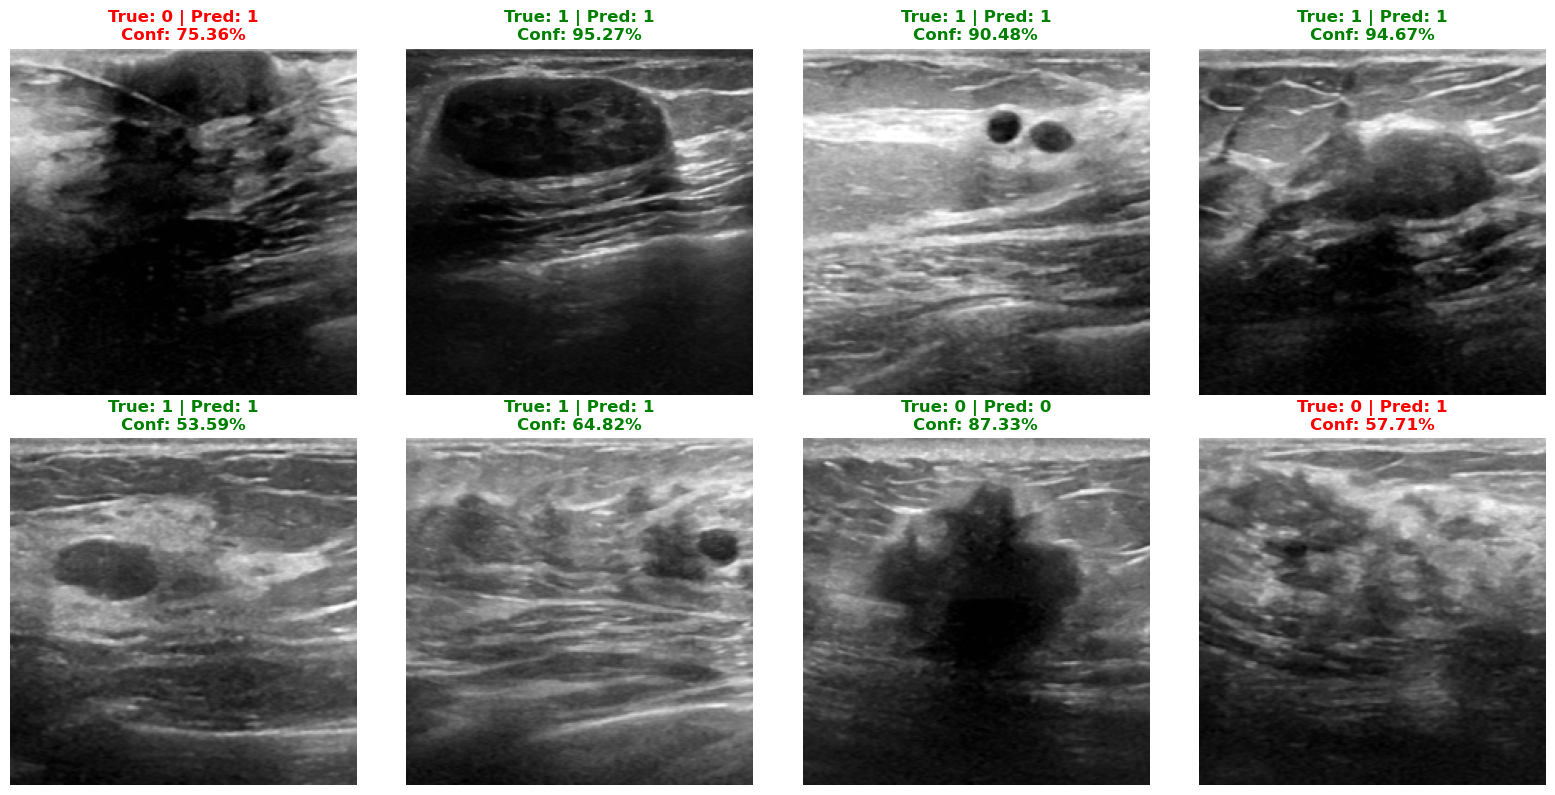

✓ Sample predictions saved to ./experiments/models/BreastMNIST/classical/shallow/sample_predictions.png


In [90]:
import numpy as np

# Get a batch of test images
dataiter = iter(test_loader)
images, labels = next(dataiter)
images, labels = images.to(device), labels.to(device)

# Make predictions
with torch.no_grad():
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)
    probs = torch.softmax(outputs, dim=1)

# Visualize
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for idx in range(min(8, len(images))):
    img = images[idx].cpu().squeeze().numpy()
    true_label = labels[idx].cpu().item()
    pred_label = predicted[idx].cpu().item()
    confidence = probs[idx][pred_label].cpu().item()
    
    axes[idx].imshow(img, cmap='gray')
    axes[idx].axis('off')
    
    color = 'green' if true_label == pred_label else 'red'
    title = f"True: {true_label} | Pred: {pred_label}\nConf: {confidence:.2%}"
    axes[idx].set_title(title, color=color, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(save_dir, 'sample_predictions.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"✓ Sample predictions saved to {save_dir}/sample_predictions.png")

## 11. Summary

In [91]:
print("\n" + "="*80)
print("TRAINING SUMMARY - Classical Model WITHOUT Encoder")
print("="*80)
print(f"\nModel: {model.__class__.__name__}")
print(f"Dataset: {CONFIG['dataset'].upper()}")
print(f"Encoder: None (end-to-end training)")
print(f"\nArchitecture:")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"\nBest Validation Results:")
print(f"  Accuracy: {max(history['val_acc']):.4f}")
print(f"  F1 Score: {max(history['val_f1']):.4f}")
print(f"  AUC: {max(history['val_auc']):.4f}")
print(f"\nFinal Test Results:")
print(f"  Accuracy: {test_metrics['accuracy']:.4f}")
print(f"  F1 Score: {test_metrics['f1']:.4f}")
print(f"  AUC: {test_metrics['auc']:.4f}")
print(f"\nModel saved at: {save_dir}")
print("="*80)


TRAINING SUMMARY - Classical Model WITHOUT Encoder

Model: ShallowCNN
Dataset: BREASTMNIST
Encoder: None (end-to-end training)

Architecture:
  Total parameters: 93,378
  Trainable parameters: 93,378

Best Validation Results:
  Accuracy: 0.8974
  F1 Score: 0.9298
  AUC: 0.9365

Final Test Results:
  Accuracy: 0.8397
  F1 Score: 0.8918
  AUC: 0.8626

Model saved at: ./experiments/models/BreastMNIST/classical/shallow
